<div dir="rtl" lang="he" align="right" style="direction:rtl;text-align:right;line-height:1.75">
<h2 dir="rtl" align="right">פרויקט 3: Wikimedia Streaming דרך Confluent Cloud</h2>
<div dir="rtl" align="right" style="text-align:right;margin-bottom:0.9em">זוהי גרסת הענן של מחברת 02. מקור האירועים נשאר Wikimedia, וה־Consumer ממשיך לכתוב ל־OpenSearch. השינוי המרכזי הוא ששרת Kafka מנוהל כעת ב־Confluent Cloud, והחיבור אליו מוצפן ומאומת באמצעות API Key של Kafka.</div><div dir="rtl" align="right" style="text-align:right;margin-bottom:0.9em"><strong>מפת המיקום:</strong> קוד Python רץ ב־Cursor במחשב שלכם; Kafka פועל בענן; OpenSearch נשאר מקומי ב־Docker כברירת מחדל. אין צורך להפעיל את מכולת Kafka המקומית עבור המחברת הזאת.</div><div dir="rtl" align="right" style="text-align:right;margin-bottom:0.9em">הקליטה נמשכת ללא מגבלת כמות או זמן כוללת, עד עצירה יזומה, סיום המקור או שגיאה מפורשת. השימוש בענן עשוי להיות בתשלום; עצירת המחברת אינה מוחקת את משאבי הענן או מפסיקה בהכרח את חיובם.</div><div dir="rtl" align="right" style="text-align:right;margin-bottom:0.9em">המחברת מתאימה ל־Cursor + uv + Python 3.13.12. מומלץ להבין קודם את מחברת 02, אבל אפשר להפעיל את מחברת 03 בנפרד לאחר השלמת ההכנה.</div>
</div>


<div dir="rtl" lang="he" align="right" style="direction:rtl;text-align:right;line-height:1.75">
<h2 dir="rtl" align="right">המסלול: מקור חי, Kafka בענן ויעד חיפוש</h2>
<div dir="rtl" align="right" style="text-align:right;margin-bottom:0.9em">ה־Producer שולח אירוע אחד בכל פעם לשרת בענן. ה־Consumer במחשב קורא מהענן וכותב את האירוע ל־OpenSearch. רק לאחר אישור הכתיבה הוא שומר Commit ב־Kafka שבענן.</div><div dir="rtl" align="right" style="text-align:right;margin-bottom:0.9em">הענן מנהל את שרתי Kafka; הוא אינו מפעיל את תאי המחברת. סגירת Cursor או המחשב עוצרת את קוד Python.</div>
</div>

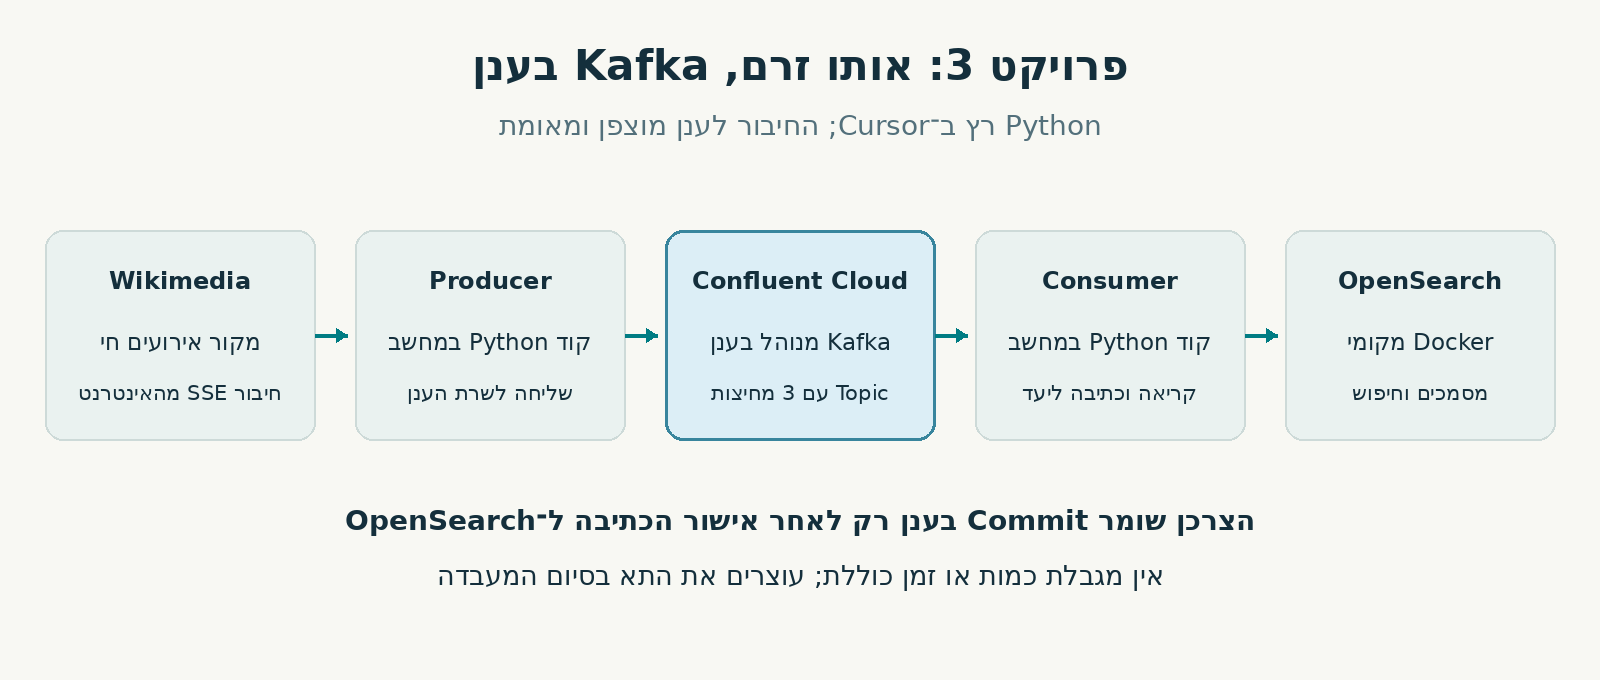



<div dir="rtl" lang="he" align="right" style="direction:rtl;text-align:right;line-height:1.75">
<h2 dir="rtl" align="right">לפני ההרצה: מה מכינים ב־Confluent Cloud?</h2>
<ol dir="rtl" align="right"><li>פותחים חשבון ובוחרים Environment ואשכול Kafka המתאים למעבדה. לעבודה ישירה מהמחשב נדרש Endpoint נגיש; במסלול הזה משתמשים בחיבור Public.</li><li>יוצרים Topic בשם <code dir="ltr">python.wikimedia.cloud.v1</code> עם שלוש מחיצות. השכפול מנוהל בענן. המחברת בודקת Topic קיים ואינה יוצרת Topic בענן.</li><li>מכינים Service Account והרשאות קריאה, כתיבה ו־Describe ל־Topic, וקריאה לקבוצת הצרכנים <code dir="ltr">python-wikimedia-cloud-opensearch-v1</code>.</li><li>יוצרים API Key מסוג Kafka עבור האשכול הנכון. שומרים את ה־Key ואת ה־Secret בקובץ החיבור המקומי.</li><li>מעתיקים את Bootstrap server מתצורת לקוח Python, למשל כתובת DNS המסתיימת בפורט 9092. אין להשתמש בכתובת אתר ה־Console או ב־REST endpoint.</li></ol><div dir="rtl" align="right" style="text-align:right;margin-bottom:0.9em">הוראות מפורטות, הרשאות, תקלות ועלויות: <a href="docs/CONFLUENT_CLOUD_HE.md">מדריך החיבור ל־Confluent Cloud</a>. המדריך מבדיל בין הרשאות הניהול החד־פעמיות לבין הרשאות התהליך בזמן ההרצה.</div><div dir="rtl" align="right" style="text-align:right;margin-bottom:0.9em">במעבדה כיתתית, לכל קבוצה מומלץ Topic ו־Consumer Group משלה. אם שיניתם שמות, עדכנו אותם גם בתא ההגדרות וגם בהרשאות.</div>
</div>


<div dir="rtl" lang="he" align="right" style="direction:rtl;text-align:right;line-height:1.75">
<h2 dir="rtl" align="right">קובץ החיבור המקומי</h2>
<div dir="rtl" align="right" style="text-align:right;margin-bottom:0.9em">בתיקיית הפרויקט נמצא קובץ דוגמה בשם <code dir="ltr">confluent-cloud.properties.example</code>. יוצרים ממנו עותק בשם <code dir="ltr">confluent-cloud.properties</code> רק אם העותק עדיין אינו קיים:</div></div>

```powershell
if (-not (Test-Path confluent-cloud.properties)) {
    Copy-Item confluent-cloud.properties.example confluent-cloud.properties
}
```

<div dir="rtl" lang="he" align="right">
<div dir="rtl" align="right" style="text-align:right;margin-bottom:0.9em">פותחים את העותק ב־Cursor ומחליפים את ערכי הדוגמה: <code dir="ltr">bootstrap.servers</code>, <code dir="ltr">sasl.username</code> ו־<code dir="ltr">sasl.password</code>. השאירו <code dir="ltr">security.protocol=SASL_SSL</code> ו־<code dir="ltr">sasl.mechanism=PLAIN</code>.</div><div dir="rtl" align="right" style="text-align:right;margin-bottom:0.9em">זהו קובץ טקסט בפורמט <code dir="ltr">key=value</code>, ללא מרכאות מסביב לערכים. ה־Key משמש שם משתמש וה־Secret משמש סיסמה. אלה אינם פרטי הכניסה האישיים לאתר Confluent.</div><div dir="rtl" align="right" style="text-align:right;margin-bottom:0.9em">קובץ החיבור האמיתי מוחרג מ־Git. אין להדביק מפתחות בתאי המחברת, להדפיס את מילון החיבור או לצרף את קובץ הסודות להגשה. פלט התא הבא מציג רק פרטי חיבור שאינם סודיים.</div>
</div>


<div dir="rtl" lang="he" align="right" style="direction:rtl;text-align:right;line-height:1.75">
<h2 dir="rtl" align="right">הכנת Python ו־OpenSearch במחשב</h2>
<div dir="rtl" align="right" style="text-align:right;margin-bottom:0.9em">פתחו את כל תיקיית הפרויקט ב־Cursor ובחרו Kernel מתוך <code dir="ltr">.venv</code>. פתחו Docker Desktop כדי להפעיל את OpenSearch המקומי. במסוף הפרויקט:</div></div>

```powershell
uv python install 3.13.12
uv sync --locked
uv run --locked python scripts/opensearch_docker.py start
```

<div dir="rtl" lang="he" align="right">
<div dir="rtl" align="right" style="text-align:right;margin-bottom:0.9em">אין כאן פקודת הפעלה ל־Kafka מקומי: ה־Producer וה־Consumer יתחברו לכתובת הענן מקובץ החיבור. התקנת ספריית confluent-kafka אינה דורשת התקנת שרת Kafka במחשב.</div><div dir="rtl" align="right" style="text-align:right;margin-bottom:0.9em">לשרת OpenSearch מקומי דרושים תנאי Docker המתוארים ב־<a href="Kafka_Installation_Guide_HE.html">מדריך ההתקנה</a>. כתובת ברירת המחדל היא <code dir="ltr">http://127.0.0.1:9200</code>.</div><div dir="rtl" align="right" style="text-align:right;margin-bottom:0.9em">אפשר להגדיר שרת OpenSearch חיצוני דרך משתנה הסביבה <code dir="ltr">OPENSEARCH_URL</code>. יעד חיצוני מחייב HTTPS ותעודה תקינה; פרטי אימות בסיסי, אם נדרשים, נקראים מ־<code dir="ltr">OPENSEARCH_USERNAME</code> ומ־<code dir="ltr">OPENSEARCH_PASSWORD</code>. שירות הדורש AWS SigV4 אינו נתמך אוטומטית בלקוח הזה.</div>
</div>


<div dir="rtl" lang="he" align="right" style="direction:rtl;text-align:right;line-height:1.75">
<h2 dir="rtl" align="right">1. טוענים את פרטי החיבור ומגדירים את הניסוי</h2>
<div dir="rtl" align="right" style="text-align:right;margin-bottom:0.9em">הטוען בודק שהקובץ מכיל כתובת שרת, מפתח וסוד, ושהחיבור משתמש ב־TLS מאומת. ערכי הדוגמה אינם מתקבלים. אם הקובץ חסר או שגוי, מתקבלת הודעה לפני פנייה לשירותים; אין מעבר אוטומטי ל־Kafka המקומי.</div><div dir="rtl" align="right" style="text-align:right;margin-bottom:0.9em">למסלול הענן יש שמות נפרדים מאלה של מחברת 02, כדי שלא לערבב נתונים מקומיים עם נתוני הענן. שמרו על אותם שמות בין הרצות כדי להמשיך מאותה התקדמות.</div><div dir="rtl" align="right" style="text-align:right;margin-bottom:0.9em"><code dir="ltr">MAX_EVENTS = None</code> ו־<code dir="ltr">MAX_SECONDS = None</code> משאירים את הקליטה רציפה. אפשר לסנן בצד הלקוח לפי אתר באמצעות <code dir="ltr">SERVER_NAME</code>; הסינון מקטין את מה שנשלח ל־Kafka, אך אינו מבטל את החיבור לזרם המלא של Wikimedia.</div>
</div>


In [ ]:
import json
import os
import sys
import threading
from pathlib import Path
from importlib.metadata import version

from scripts.confluent_cloud import load_confluent_cloud_config, safe_connection_summary
from scripts.wikimedia_stream import iter_wikimedia_events
from scripts.kafka_opensearch_streaming import (
    OpenSearchPipelineError,
    create_opensearch_client,
    prepare_pipeline,
    run_opensearch_pipeline,
)

KAFKA_CONFIG_FILE = Path("confluent-cloud.properties")
kafka_connection = load_confluent_cloud_config(KAFKA_CONFIG_FILE)
BOOTSTRAP_SERVERS = kafka_connection["bootstrap.servers"]
OPENSEARCH_URL = os.environ.get("OPENSEARCH_URL", "http://127.0.0.1:9200")
TOPIC = "python.wikimedia.cloud.v1"
GROUP_ID = "python-wikimedia-cloud-opensearch-v1"
INDEX = "wikimedia-cloud-recentchanges-v1"
SERVER_NAME = None  # Optional client-side filter: "he.wikipedia.org"
MAX_EVENTS = None
MAX_SECONDS = None
PROGRESS_EVERY = 25

print("Python:", sys.version.split()[0], "| target: 3.13.12")
print("Kernel:", sys.executable)
for package in ("confluent-kafka", "requests", "opensearch-py"):
    print(package, version(package))
if sys.version_info[:3] != (3, 13, 12):
    print("Select the project .venv Kernel for Python 3.13.12.")
print("Kafka connection:", safe_connection_summary(kafka_connection))
print("Topic:", TOPIC, "| Consumer group:", GROUP_ID, "| Index:", INDEX)


<div dir="rtl" lang="he" align="right" style="direction:rtl;text-align:right;line-height:1.75">
<h2 dir="rtl" align="right">2. בודקים חיבור לענן ומכינים את OpenSearch</h2>
<div dir="rtl" align="right" style="text-align:right;margin-bottom:0.9em">הבדיקה פונה ל־Topic שהכנתם ב־Confluent Cloud עם אותם פרטי SASL/TLS שבהם ישתמשו גם השולח וגם הצרכן. היא דורשת שלוש מחיצות ומנהיגים זמינים, ואינה יוצרת או משנה Topic בענן.</div><div dir="rtl" align="right" style="text-align:right;margin-bottom:0.9em">ב־OpenSearch נוצר Index מקומי חסר עם סכמה מפורשת. Index קיים נבדק להתאמה. אם הבדיקה נכשלת, פותרים את שגיאת החיבור, האימות, ההרשאות או ה־Mapping לפני הפעלת הזרם.</div><div dir="rtl" align="right" style="text-align:right;margin-bottom:0.9em">בדיקת Metadata מוצלחת מוכיחה שניתן לתאר את ה־Topic. הרשאות הכתיבה, הקריאה וה־Commit נבדקות בפועל בעת הרצת השולח והצרכן; אין להסיק אותן מבדיקת Metadata לבדה.</div>
</div>


In [ ]:
preflight = prepare_pipeline(
    topic=TOPIC,
    bootstrap_servers=BOOTSTRAP_SERVERS,
    kafka_config=kafka_connection,
    create_topic=False,
    replication_factor=3,
    partitions=3,
    ready_timeout=60,
    opensearch_url=OPENSEARCH_URL,
    index=INDEX,
)
print(json.dumps(preflight, indent=2))


<div dir="rtl" lang="he" align="right" style="direction:rtl;text-align:right;line-height:1.75">
<h2 dir="rtl" align="right">3. איזה מסמך נכתב ל־OpenSearch?</h2>
<table dir="rtl" width="100%"><tr><td dir="rtl" align="right" width="35%">שדה</td><td dir="rtl" align="right" width="65%">משמעות</td></tr><tr><td dir="rtl" align="right" width="35%"><code dir="ltr">event_id</code></td><td dir="rtl" align="right" width="65%">מזהה האירוע המקורי מתוך meta.id.</td></tr><tr><td dir="rtl" align="right" width="35%"><code dir="ltr">event_time</code></td><td dir="rtl" align="right" width="65%">זמן האירוע מתוך meta.dt, שעליו מבוססים מיון וחלונות זמן.</td></tr><tr><td dir="rtl" align="right" width="35%"><code dir="ltr">server_name</code></td><td dir="rtl" align="right" width="65%">האתר שממנו הגיע האירוע.</td></tr><tr><td dir="rtl" align="right" width="35%"><code dir="ltr">bot</code></td><td dir="rtl" align="right" width="65%">הסימון המקורי של האירוע כבוט או כפעילות אחרת.</td></tr><tr><td dir="rtl" align="right" width="35%"><code dir="ltr">title, type, wiki, namespace</code></td><td dir="rtl" align="right" width="65%">שדות תוכן נבחרים לצורך חיפוש וניתוח.</td></tr><tr><td dir="rtl" align="right" width="35%"><code dir="ltr">kafka_topic, kafka_partition, kafka_offset</code></td><td dir="rtl" align="right" width="65%">המיקום שבו הצרכן קרא את הרשומה.</td></tr><tr><td dir="rtl" align="right" width="35%"><code dir="ltr">indexed_at</code></td><td dir="rtl" align="right" width="65%">הזמן שבו היישום הכין את המסמך לכתיבה.</td></tr></table><div dir="rtl" align="right" style="text-align:right;margin-bottom:0.9em">ה־Index משתמש בסכמה מפורשת. מזהה המסמך הוא SHA-256 של event_id, ולכן כתיבה חוזרת של אותו אירוע מעדכנת את אותו מסמך. זה מאפשר התאוששות מכשל בין הכתיבה לבין Commit, אך אינו יוצר עסקה אחת בין שני השרתים.</div>
</div>

<div dir="rtl" lang="he" align="right" style="direction:rtl;text-align:right;line-height:1.75">
<h2 dir="rtl" align="right">4. מפעילים Streaming דרך הענן</h2>
<div dir="rtl" align="right" style="text-align:right;margin-bottom:0.9em"><strong>התא הבא נשאר פעיל בכוונה.</strong> ה־Producer קולט ושולח בזמן שה־Consumer קורא מ־Confluent Cloud וכותב ל־OpenSearch. אין איסוף של כל האירועים לרשימה, ואין מגבלת כמות או זמן כוללת.</div><div dir="rtl" align="right" style="text-align:right;margin-bottom:0.9em">כל 25 כתיבות, וכן בעדכוני מצב תקופתיים, מופיע דוח התקדמות. הרשאות ענן שגויות או כשל כתיבה מפסיקים את התהליך עם דוח חלקי; אין החלפה לנתוני דוגמה או לשרת המקומי.</div><div dir="rtl" align="right" style="text-align:right;margin-bottom:0.9em">עוצרים באמצעות כפתור העצירה של התא, וממתינים לסיום ניקוז התורים וסגירת הלקוחות. זמני הרשת והסגירה מוגבלים, אך תקלה ברשת יכולה להאריך את ההמתנה. אם הפעלתם Run All, הריצו את תאי החיפוש שאחרי התא ידנית לאחר העצירה.</div><div dir="rtl" align="right" style="text-align:right;margin-bottom:0.9em">אותו Topic וקבוצה נשמרים בין הרצות. לכן הצרכן עשוי לעבד גם רשומות ישנות שכבר נמצאות בענן, ומספר הכתיבות עשוי לעלות על מספר האירועים שקלט השולח הנוכחי.</div>
</div>


In [ ]:
source_stats = {}
stop_event = threading.Event()
stream_report = None

def show_progress(report):
    keys = ("accepted", "confirmed", "consumed", "indexed", "committed",
            "committed_current_run", "consumed_other_runs")
    print("STREAM", {key: report.get(key) for key in keys}, flush=True)

events = iter_wikimedia_events(
    max_events=MAX_EVENTS,
    max_seconds=MAX_SECONDS,
    server_name=SERVER_NAME,
    stats=source_stats,
    stop_event=stop_event,
)
try:
    stream_report = run_opensearch_pipeline(
        events,
        topic=TOPIC,
        bootstrap_servers=BOOTSTRAP_SERVERS,
        kafka_config=kafka_connection,
        create_topic=False,
        replication_factor=3,
        delivery_timeout_seconds=60,
        opensearch_url=OPENSEARCH_URL,
        index=INDEX,
        group_id=GROUP_ID,
        stop_event=stop_event,
        on_progress=show_progress,
        progress_every=PROGRESS_EVERY,
        preflight=False,
    )
except OpenSearchPipelineError as exc:
    stream_report = exc.report
    print("Pipeline failed at stage:", exc.stage)
    raise
finally:
    stop_event.set()
    events.close()
    print("SOURCE", {key: source_stats.get(key) for key in
          ("received", "invalid", "filtered", "reconnects",
           "dedup_cache_size", "dedup_evictions", "stop_reason")})


<div dir="rtl" lang="he" align="right" style="direction:rtl;text-align:right;line-height:1.75">
<h2 dir="rtl" align="right">5. פירוש דוח ההרצה</h2>
<table dir="rtl" width="100%"><tr><td dir="rtl" align="right" width="35%">מונה</td><td dir="rtl" align="right" width="65%">מה הוא אומר</td></tr><tr><td dir="rtl" align="right" width="35%"><code dir="ltr">accepted</code></td><td dir="rtl" align="right" width="65%">כמה רשומות נכנסו לתור השולח בהרצה הנוכחית.</td></tr><tr><td dir="rtl" align="right" width="35%"><code dir="ltr">confirmed</code></td><td dir="rtl" align="right" width="65%">כמה רשומות קיבלו אישור מסירה מ־Kafka.</td></tr><tr><td dir="rtl" align="right" width="35%"><code dir="ltr">consumed</code></td><td dir="rtl" align="right" width="65%">כמה רשומות הצרכן קרא, כולל נתונים קודמים שממתינים ב־Topic.</td></tr><tr><td dir="rtl" align="right" width="35%"><code dir="ltr">indexed</code></td><td dir="rtl" align="right" width="65%">כמה פעולות כתיבה ל־OpenSearch קיבלו אישור.</td></tr><tr><td dir="rtl" align="right" width="35%"><code dir="ltr">committed</code></td><td dir="rtl" align="right" width="65%">כמה רשומות הושלמו ושמירת מיקום ההמשך שלהן אושרה.</td></tr><tr><td dir="rtl" align="right" width="35%"><code dir="ltr">committed_current_run</code></td><td dir="rtl" align="right" width="65%">כמה רשומות שהשולח הנוכחי שלח הושלמו על ידי הצרכן.</td></tr><tr><td dir="rtl" align="right" width="35%"><code dir="ltr">consumed_other_runs</code></td><td dir="rtl" align="right" width="65%">כמה רשומות הגיעו מהרצות קודמות או משולחים אחרים.</td></tr></table><div dir="rtl" align="right" style="text-align:right;margin-bottom:0.9em">מספר פעולות Index אינו בהכרח מספר המסמכים הייחודיים. כתיבה חוזרת לאותו מזהה נספרת כפעולת כתיבה נוספת. גם מספר המסמכים ב־Index עשוי לכלול הרצות קודמות.</div><div dir="rtl" align="right" style="text-align:right;margin-bottom:0.9em">לאחר עצירה הריצו את תאי הבדיקה הבאים ידנית אם Cursor ביטל את המשך Run All. זמן הסגירה כולל המתנה מוגבלת לשליחות ולצרכן. נתונים שנשארו ב־Kafka יכולים להמתין להפעלה הבאה.</div>
</div>

In [ ]:
if stream_report is None:
    print("No final report yet. Start the stream cell, then stop it normally.")
else:
    print(json.dumps(stream_report, indent=2, default=str))

<div dir="rtl" lang="he" align="right" style="direction:rtl;text-align:right;line-height:1.75">
<h2 dir="rtl" align="right">6. שואלים את OpenSearch לאחר העצירה</h2>
<div dir="rtl" align="right" style="text-align:right;margin-bottom:0.9em">הנתונים שנשמרו נשלפים מ־OpenSearch. הפעלת Kafka בענן אינה משנה את שאילתות החיפוש. Refresh מאפשר לראות כתיבות שהסתיימו לאחרונה; מבצעים אותו פעם אחת בתרגיל, ולא אחרי כל אירוע.</div><div dir="rtl" align="right" style="text-align:right;margin-bottom:0.9em">בברירת המחדל המקומית אפשר לראות את מספר המסמכים גם בזמן הקליטה בכתובת <code dir="ltr">http://127.0.0.1:9200/wikimedia-cloud-recentchanges-v1/_count</code>. המספר כולל מסמכים מהרצות קודמות באותו Index ואינו זהה בהכרח למספר פעולות הכתיבה בהרצה הנוכחית.</div>
</div>


In [ ]:
client = create_opensearch_client(OPENSEARCH_URL)
try:
    client.indices.refresh(index=INDEX)
    print("Documents in index:", client.count(index=INDEX)["count"])
    latest = client.search(index=INDEX, body={
        "size": 5,
        "sort": [{"event_time": {"order": "desc"}}],
        "_source": ["event_id", "event_time", "server_name", "bot", "title"],
        "query": {"match_all": {}},
    })
    for hit in latest["hits"]["hits"]:
        print(json.dumps(hit["_source"], ensure_ascii=False))
finally:
    client.close()

<div dir="rtl" lang="he" align="right" style="direction:rtl;text-align:right;line-height:1.75">
<h2 dir="rtl" align="right">7. חיפוש לפי אתר</h2>
<div dir="rtl" align="right" style="text-align:right;margin-bottom:0.9em">שם האתר מוגדר כשדה keyword, ולכן משתמשים בשאילתת term על שם השדה עצמו. אם אין תוצאות, ייתכן שלא נקלטו אירועים מהאתר שבחרנו. אפשר לבחור אתר שהופיע בתא הקודם.</div>
</div>

In [ ]:
SEARCH_SITE = "he.wikipedia.org"
client = create_opensearch_client(OPENSEARCH_URL)
try:
    matches = client.search(index=INDEX, body={
        "size": 5,
        "query": {"term": {"server_name": SEARCH_SITE}},
        "sort": [{"event_time": {"order": "desc"}}],
        "_source": ["event_time", "server_name", "title", "bot"],
    })
    print("Matching documents:", matches["hits"]["total"])
    for hit in matches["hits"]["hits"]:
        print(json.dumps(hit["_source"], ensure_ascii=False))
finally:
    client.close()

<div dir="rtl" lang="he" align="right" style="direction:rtl;text-align:right;line-height:1.75">
<h2 dir="rtl" align="right">8. סיכומים בתוך OpenSearch</h2>
<div dir="rtl" align="right" style="text-align:right;margin-bottom:0.9em">בפרויקט הראשון ספרנו עשרה מילונים בפייתון. כאן OpenSearch סופר את המסמכים שנשמרו: פעילות לפי אתר, בוטים ופעילות בכל דקה. אין צורך להוריד את כל המסמכים אל המחברת.</div><div dir="rtl" align="right" style="text-align:right;margin-bottom:0.9em">השאילתה מוגבלת לחמש עשרה הדקות האחרונות לפי זמן האירוע. סכומי Top 10 של אתרים אינם בהכרח כל האירועים. זו תמונת מצב של המסמכים הזמינים לחיפוש, ללא Watermark או סגירה סופית של חלונות.</div>
</div>

In [ ]:
client = create_opensearch_client(OPENSEARCH_URL)
try:
    summary = client.search(index=INDEX, body={
        "size": 0,
        "query": {"range": {"event_time": {"gte": "now-15m", "lte": "now"}}},
        "aggs": {
            "by_site": {"terms": {"field": "server_name", "size": 10}},
            "by_bot": {"terms": {"field": "bot"}},
            "per_minute": {"date_histogram": {
                "field": "event_time", "fixed_interval": "1m", "min_doc_count": 1}},
        },
    })
    print(json.dumps(summary["aggregations"], indent=2, ensure_ascii=False))
finally:
    client.close()

<div dir="rtl" lang="he" align="right" style="direction:rtl;text-align:right;line-height:1.75">
<h2 dir="rtl" align="right">9. עוצרים, ממשיכים ומבינים מה נשאר בענן</h2>
<div dir="rtl" align="right" style="text-align:right;margin-bottom:0.9em">לאחר עצירה מסודרת, אותה קבוצת צרכנים ממשיכה מהמיקום השמור ב־Kafka שבענן, כל עוד המיקום והנתונים עדיין תקפים. אירועים שכבר הגיעו ל־Kafka יכולים להמתין לצרכן; הזמינות תלויה גם במדיניות Retention.</div><div dir="rtl" align="right" style="text-align:right;margin-bottom:0.9em">סמן Wikimedia נשמר בזיכרון בלבד במהלך ההרצה. אתחול Kernel אינו משחזר אותו, ואין כאן הבטחה להשלמת האירועים שהתרחשו במקור בזמן שהתהליך לא פעל.</div><div dir="rtl" align="right" style="text-align:right;margin-bottom:0.9em">זיכרון העבודה מוגבל, אבל אחסון בענן וב־OpenSearch עשוי לגדול. גם תעבורה שנכתבת לענן או נקראת ממנו יכולה להיות מחויבת. עצירת התא או OpenSearch המקומי אינה מוחקת את האשכול או את ה־Topic ב־Confluent Cloud.</div><div dir="rtl" align="right" style="text-align:right;margin-bottom:0.9em">בסיום המעבדה בדקו את המשאבים ואת החיובים ב־Confluent Cloud. מחיקת משאבים מוחקת נתונים ועלולה להשפיע על אחרים; מבצעים אותה דרך מנהל החשבון בהתאם לשימוש בפועל. המחברת אינה מוחקת משאבים אוטומטית.</div></div>

```powershell
uv run --locked python scripts/opensearch_docker.py stop
```

<div dir="rtl" lang="he" align="right">

</div>


<div dir="rtl" lang="he" align="right" style="direction:rtl;text-align:right;line-height:1.75">
<h2 dir="rtl" align="right">תרגילים להשוואה בין מקומי לענן</h2>
<ol dir="rtl" align="right"><li>אילו רכיבים עברו לענן, ואילו עדיין פועלים במחשב שלכם?</li><li>למה חיבור Metadata מוצלח אינו מוכיח שהצרכן מורשה לבצע Commit?</li><li>עצרו והפעילו שוב עם אותה קבוצה. כיצד נראית ההתקדמות ב־Kafka, ומדוע חלק מהאירועים עשויים להיקרא שוב?</li><li>מה קורה אם OpenSearch כתב מסמך וה־Commit בענן נכשל?</li><li>איך מפרידים בין קבוצות סטודנטים באותו אשכול באמצעות שמות והרשאות?</li><li>מה צריך לשנות כדי שהתהליך ימשיך לפעול גם לאחר שסוגרים את המחשב?</li></ol>
</div>


<div dir="rtl" lang="he" align="right" style="direction:rtl;text-align:right;line-height:1.75">
<h2 dir="rtl" align="right">מקורות והמשך עבודה</h2>
<ul dir="rtl" align="right"><li><a href="docs/CONFLUENT_CLOUD_HE.md">מדריך החיבור, ההרשאות ופתרון התקלות</a></li><li><a href="02_Wikimedia_Streaming_OpenSearch_HE.ipynb">מחברת 02 — אותו תהליך עם Kafka מקומי</a></li><li><a href="https://docs.confluent.io/cloud/current/cp-component/clients-cloud-config.html">Confluent — חיבור לקוחות Python לענן</a></li><li><a href="https://docs.confluent.io/cloud/current/client-apps/client-configs.html">Confluent — TLS והגדרות חיבור</a></li><li><a href="https://docs.confluent.io/cloud/current/security/access-control/acls/overview.html">Confluent — הרשאות Kafka ACL</a></li><li><a href="https://wikitech.wikimedia.org/wiki/Event_Platform/EventStreams">Wikimedia EventStreams</a></li><li><a href="https://docs.opensearch.org/latest/api-reference/document-apis/index-document/">OpenSearch — Index Document API</a></li></ul><div dir="rtl" align="right" style="text-align:right;margin-bottom:0.9em">מחברות 02 ו־03 משתמשות באותו runner ובאותו מקור Wikimedia. קובץ <code dir="ltr">scripts/confluent_cloud.py</code> מוסיף טעינה ואימות של הגדרות החיבור לענן. פרטי הגישה נקראים רק מקובץ החיבור המקומי.</div>
</div>
